# Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import copy
from pathlib import Path

import partitura as pt
import partitura.score
import partitura.performance

In [3]:
NASAP_PATH = Path("/home/gerel/Documents/datasets/nasap-dataset")
SCORE_PATH = NASAP_PATH / "Bach/Fugue/bwv_867/xml_score.musicxml"
score = pt.load_musicxml(SCORE_PATH)

In [4]:
# Print parts
for part in score.parts:
    print(part)
    
part = score.parts[0]
part: pt.io.Part = pt.score.unfold_part_maximal(part)

Part id="P1" name="Piano"


In [6]:
# Print measures
for measure in part.measures:
    print(measure)

0--32 Measure number=1 name=1
32--64 Measure number=2 name=2
64--96 Measure number=3 name=3
96--128 Measure number=4 name=4
128--160 Measure number=5 name=5
160--192 Measure number=6 name=6
192--224 Measure number=7 name=7
224--256 Measure number=8 name=8
256--288 Measure number=9 name=9
288--320 Measure number=10 name=10
320--352 Measure number=11 name=11
352--384 Measure number=12 name=12
384--416 Measure number=13 name=13
416--448 Measure number=14 name=14
448--480 Measure number=15 name=15
480--512 Measure number=16 name=16
512--544 Measure number=17 name=17
544--576 Measure number=18 name=18
576--608 Measure number=19 name=19
608--640 Measure number=20 name=20
640--672 Measure number=21 name=21
672--704 Measure number=22 name=22
704--736 Measure number=23 name=23
736--768 Measure number=24 name=24
768--800 Measure number=25 name=25
800--832 Measure number=26 name=26
832--864 Measure number=27 name=27
864--896 Measure number=28 name=28
896--928 Measure number=29 name=29
928--960 Me

In [6]:
part.metrical_position_map(16)

(array(16), array(32))

In [7]:
from pprint import pprint

# partitura.io.importparangonada.load_alignment_from_ASAP(Path("/home/gerel/Documents/datasets/nasap-dataset/Bach/Prelude/bwv_893/Kleisen04M_note_alignments/note_alignment.tsv"))
performance, alignment = pt.load_match(SCORE_PATH.parent / "HuNY01M.match")
performance: pt.io.Performance
alignment: list[dict]
pprint(performance)
pprint(alignment)

[{'label': 'match', 'performance_id': 'n0', 'score_id': 'n2-1'},
 {'label': 'match', 'performance_id': 'n1', 'score_id': 'n3-1'},
 {'label': 'match', 'performance_id': 'n2', 'score_id': 'n7-1'},
 {'label': 'match', 'performance_id': 'n3', 'score_id': 'n8-1'},
 {'label': 'match', 'performance_id': 'n4', 'score_id': 'n9-1'},
 {'label': 'match', 'performance_id': 'n6', 'score_id': 'n11-1'},
 {'label': 'match', 'performance_id': 'n5', 'score_id': 'n15-1'},
 {'label': 'match', 'performance_id': 'n7', 'score_id': 'n12-1'},
 {'label': 'match', 'performance_id': 'n9', 'score_id': 'n13-1'},
 {'label': 'match', 'performance_id': 'n8', 'score_id': 'n16-1'},
 {'label': 'match', 'performance_id': 'n10', 'score_id': 'n14-1'},
 {'label': 'match', 'performance_id': 'n11', 'score_id': 'n18-1'},
 {'label': 'match', 'performance_id': 'n13', 'score_id': 'n19-1'},
 {'label': 'match', 'performance_id': 'n12', 'score_id': 'n22-1'},
 {'label': 'match', 'performance_id': 'n14', 'score_id': 'n20-1'},
 {'label':

In [8]:
# import partitura.utils
# 
# pt.utils.music.match_note_arrays()

In [9]:
import numpy as np

snote_array = part.note_array()
print(snote_array)
print(snote_array.dtype)
print(snote_array[0])

# get all match files
matchfiles = list(SCORE_PATH.parent.glob("*.match"))
matchfiles.sort()

# Score time from the first to the last onset
score_time = np.linspace(snote_array['onset_beat'].min(),
                         snote_array['onset_beat'].max(),
                         100)
# Include the last offset
score_time_ending = np.r_[
    score_time,
    (snote_array['onset_beat'] + snote_array['duration_beat']).max() # last offset
]

tempo_curves = np.zeros((len(matchfiles), len(score_time)))
performers = []
for i, matchfile in enumerate(matchfiles):
    # load alignment
    performance, alignment = pt.load_match(matchfile)
    ppart = performance[0]
    # Get score time to performance time map
    _, stime_to_ptime_map = pt.musicanalysis.performance_codec.get_time_maps_from_alignment(ppart, part, alignment)
    # Compute naïve tempo curve
    performance_time = stime_to_ptime_map(score_time_ending)
    tempo_curves[i, :] = 60 * np.diff(score_time_ending) / np.diff(performance_time)
    performers.append(performance.id)

[(  0.    ,  1.    ,   0.   ,  2.   ,    0,  16, 70, 3, 'n2-1')
 (  1.    ,  1.    ,   2.   ,  2.   ,   16,  16, 65, 3, 'n3-1')
 (  2.5   ,  0.5   ,   5.   ,  1.   ,   40,   8, 78, 3, 'n7-1')
 (  3.    ,  0.5   ,   6.   ,  1.   ,   48,   8, 77, 3, 'n8-1')
 (  3.5   ,  0.5   ,   7.   ,  1.   ,   56,   8, 75, 3, 'n9-1')
 (  4.    ,  1.    ,   8.   ,  2.   ,   64,  16, 65, 2, 'n15-1')
 (  4.    ,  0.5   ,   8.   ,  1.   ,   64,   8, 73, 1, 'n11-1')
 (  4.5   ,  0.5   ,   9.   ,  1.   ,   72,   8, 72, 1, 'n12-1')
 (  5.    ,  1.    ,  10.   ,  2.   ,   80,  16, 58, 2, 'n16-1')
 (  5.    ,  0.5   ,  10.   ,  1.   ,   80,   8, 73, 1, 'n13-1')
 (  5.5   ,  0.5   ,  11.   ,  1.   ,   88,   8, 75, 1, 'n14-1')
 (  6.    ,  0.5   ,  12.   ,  1.   ,   96,   8, 77, 1, 'n18-1')
 (  6.5   ,  0.5   ,  13.   ,  1.   ,  104,   8, 73, 2, 'n22-1')
 (  6.5   ,  0.25  ,  13.   ,  0.5  ,  104,   4, 76, 1, 'n19-1')
 (  6.75  ,  0.25  ,  13.5  ,  0.5  ,  108,   4, 77, 1, 'n20-1')
 (  7.    ,  0.5   ,  14.   , 

In [10]:
snote_array[0]

np.void((0.0, 1.0, 0.0, 2.0, 0, 16, 70, 3, 'n2-1'), dtype=[('onset_beat', '<f4'), ('duration_beat', '<f4'), ('onset_quarter', '<f4'), ('duration_quarter', '<f4'), ('onset_div', '<i4'), ('duration_div', '<i4'), ('pitch', '<i4'), ('voice', '<i4'), ('id', '<U256')])

[  0.   2.   4.   6.   8.  10.  12.  14.  16.  18.  20.  22.  24.  26.
  28.  30.  32.  34.  36.  38.  40.  42.  44.  46.  48.  50.  52.  54.
  56.  58.  60.  62.  64.  66.  68.  70.  72.  74.  76.  78.  80.  82.
  84.  86.  88.  90.  92.  94.  96.  98. 100. 102. 104. 106. 108. 110.
 112. 114. 116. 118. 120. 122. 124. 126. 128. 130. 132. 134. 136. 138.
 140. 142. 144. 146. 148.]


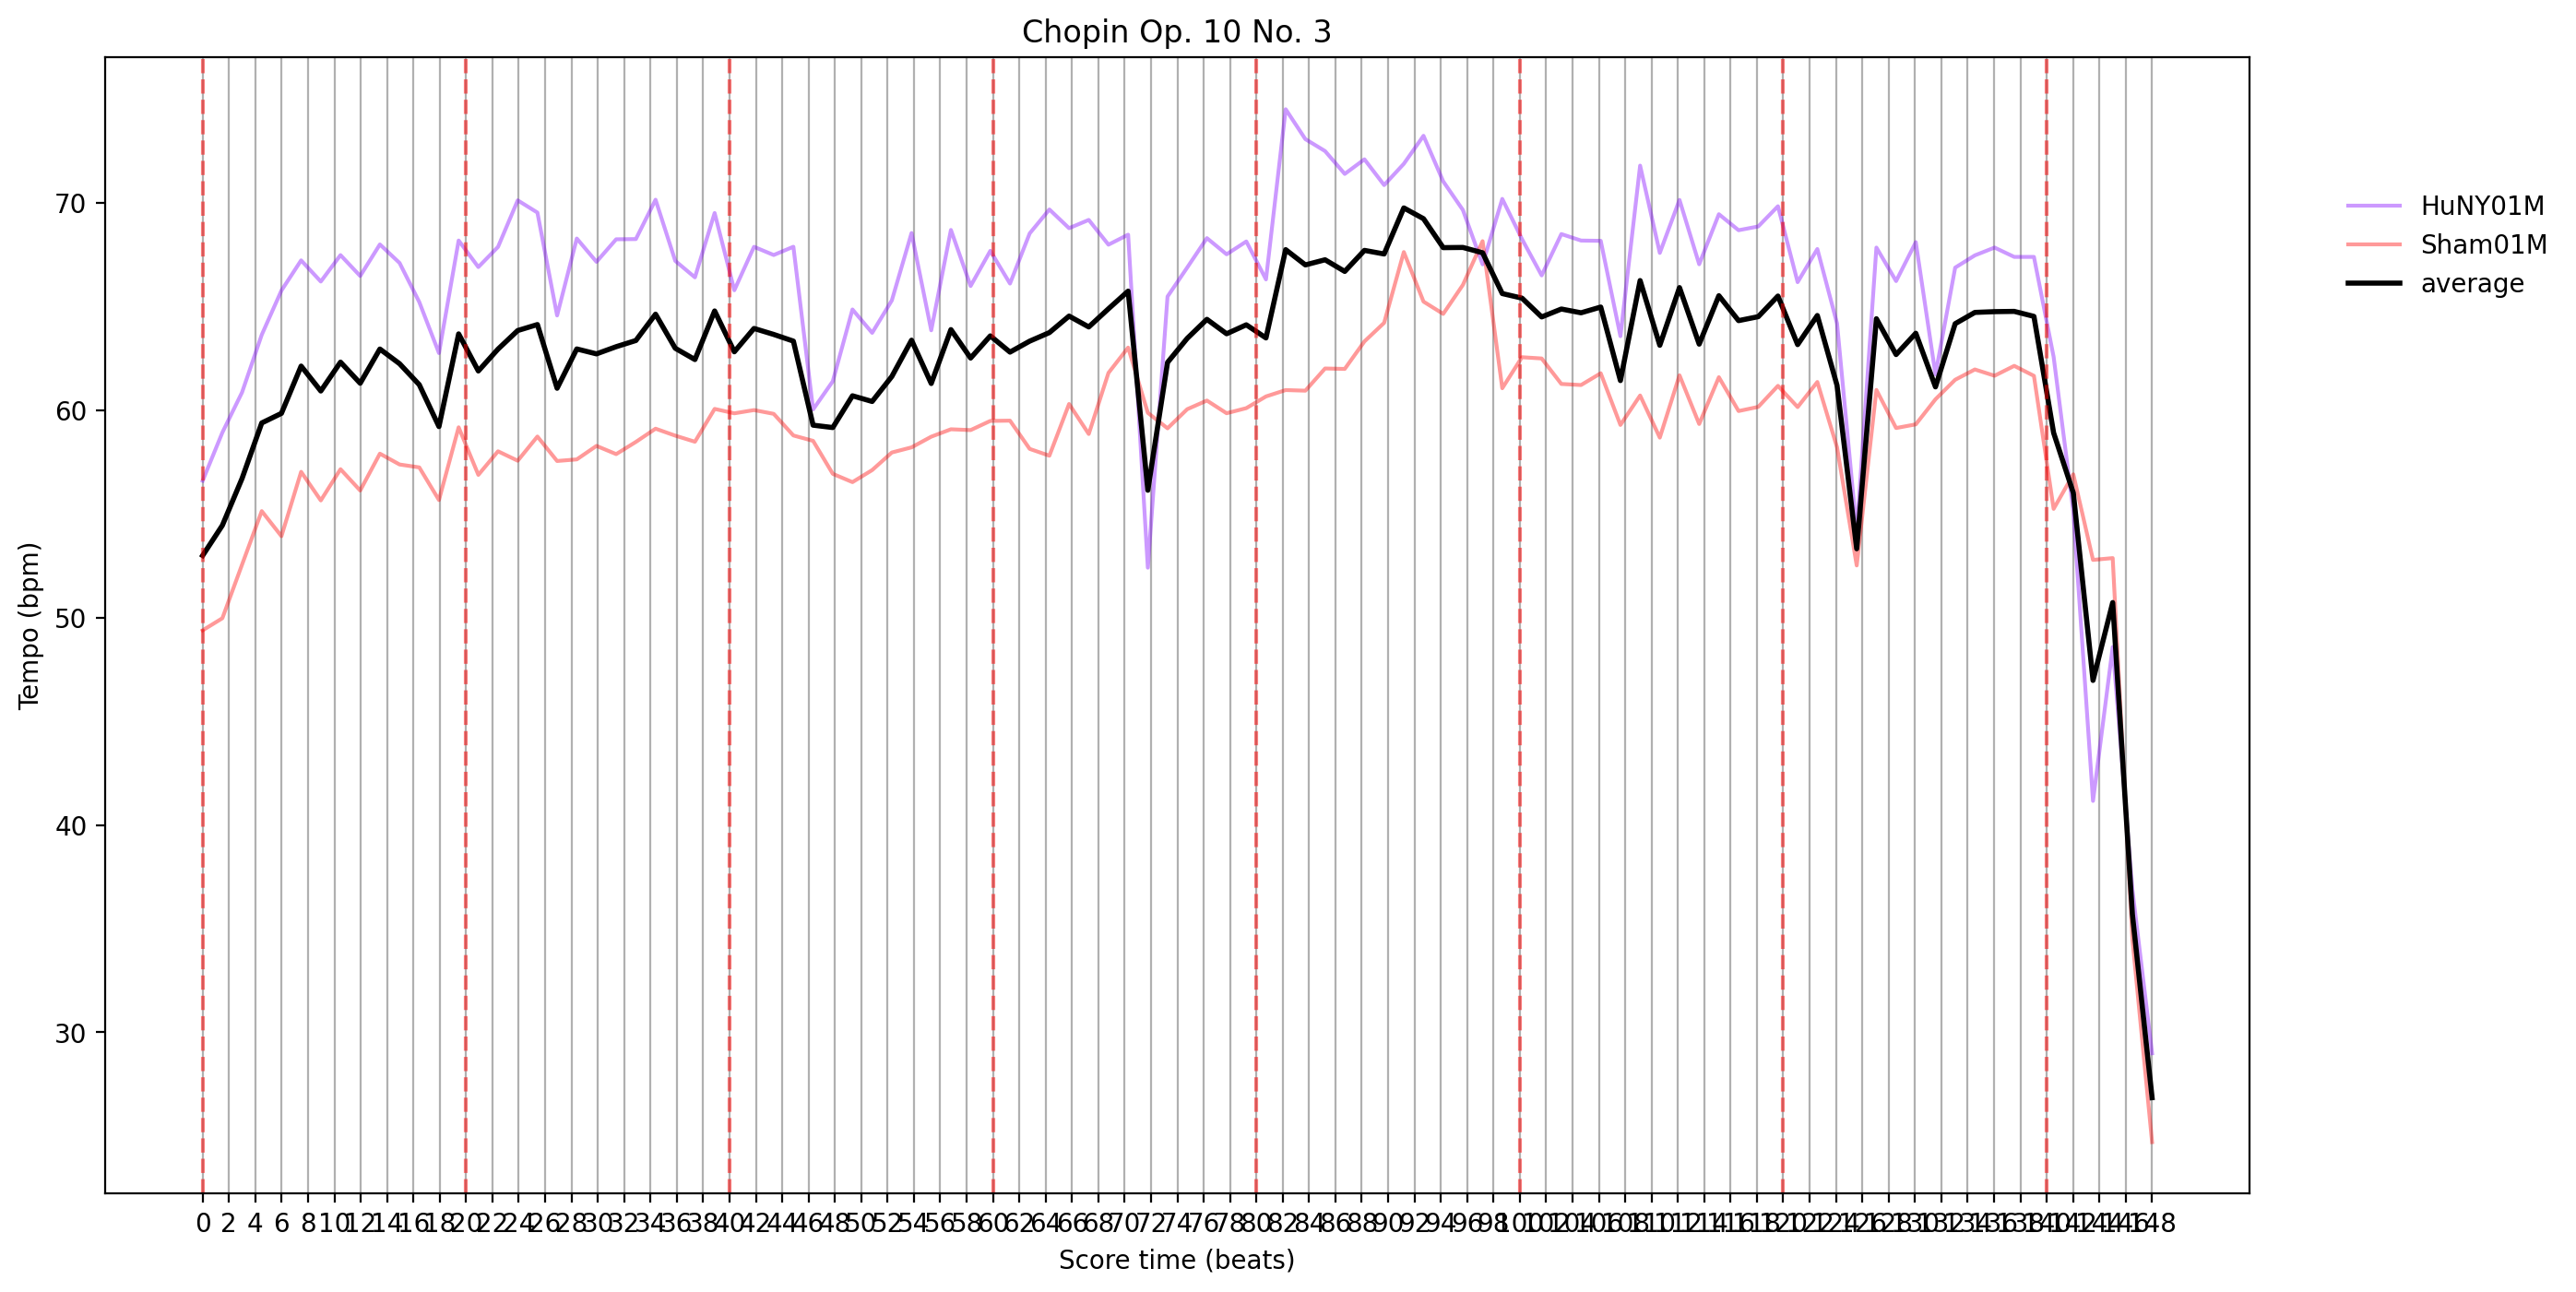

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, figsize=(15, 8))
color = plt.cm.rainbow(np.linspace(0, 1, len(tempo_curves)))
for i, tempo_curve in enumerate(tempo_curves):
    ax.plot(score_time, tempo_curve,
            label=performers[i], alpha=0.4, c=color[i])

# plot average performance
ax.plot(score_time, tempo_curves.mean(0), label='average', c='black', linewidth=2)

# get starting time of each measure in the score
measure_times = part.beat_map([measure.start.t for measure in part.iter_all(pt.score.Measure)])
print(measure_times)
# do not include pickup measure
measure_times = measure_times[measure_times >= 0]
ax.set_title('Chopin Op. 10 No. 3')
ax.set_xlabel('Score time (beats)')
ax.set_ylabel('Tempo (bpm)')
ax.set_xticks(measure_times)
# plot vlines for each 10th measure
for i in range(0, len(measure_times), 10):
    ax.axvline(measure_times[i], linestyle='--', color='red', alpha=0.5)
plt.legend(frameon=False, bbox_to_anchor = (1.15, .9))
plt.grid(axis='x')
plt.show()



# Find metric changes

In [12]:
# Disable warnings.warn
import warnings
warnings.filterwarnings("ignore")

In [13]:
# from utils.ansi_colors import Colors
# 
# # Find all scores with at least one metric change
# xmls = list(NASAP_PATH.glob("**/*.musicxml"))
# multiple = []
# for xml in xmls:
#     try:
#         s = pt.load_musicxml(xml)
#         if len(s.parts) != 1:
#             raise ValueError("Only one part expected")
#         part = s.parts[0]
#         part: pt.io.Part = pt.score.unfold_part_maximal(part)
#     except Exception as e:
#         print(f"{Colors.BOLD}{Colors.BLUE}Error loading {xml}: {e}{Colors.END}")
#         continue
#     if len(part.time_sigs) != 1:
#         print(f"{Colors.BOLD}{Colors.GREEN}{xml} - {' | '.join([f'{ts.beats}/{ts.beat_type}' for ts in part.time_sigs])} - {len(part.measures)} measures{Colors.END}")
#         multiple.append((xml, part.time_sigs))
# print(multiple)

# Split per measure

In [14]:
NEW_SCORE_PATH = Path("/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/xml_score.musicxml")

score = pt.load_musicxml(NEW_SCORE_PATH)
print(f"Score has {len(score.parts)} parts")
part = score.parts[0]
part: pt.io.Part = pt.score.unfold_part_maximal(part)
print(f"Part has {len(part.measures)} measures")
performance, alignment = pt.load_match(NEW_SCORE_PATH.parent / "Namirovsky06M.match")
print(f"Performance has {len(performance)} parts")
print(f"Alignment has {len(alignment)} elements")
performance: pt.io.Performance = performance[0]

print(part.pretty())

Score has 1 parts
Part has 41 measures
Performance has 1 parts
Alignment has 1578 elements
Part id="P1" name="Piano"
 │
 ├─ TimePoint t=0 quarter=120
 │   │
 │   └─ starting objects
 │       │
 │       ├─ 0--120 Beam
 │       ├─ 0-- Clef sign=G line=2 number=1
 │       ├─ 0-- Clef sign=G line=2 number=2
 │       ├─ 0--780 ConstantLoudnessDirection "p"
 │       ├─ 0-- KeySignature fifths=1, mode=None (G)
 │       ├─ 0--480 Measure number=1 name=1
 │       ├─ 0--24 Note id=n2-1 voice=5 staff=2 type=16th_5/4 pitch=D4
 │       ├─ 0--120 Note id=n22-1 voice=6 staff=2 type=quarter pitch=D4
 │       ├─ 0--480 Rest id=n1 voice=1 staff=1 type=
 │       ├─ 0-- TimeSignature 4/4
 │       ├─ -- Tuplet start=n2-1 end=n6-1
 │       └─ 0-- Words "Moderato."
 │
 ├─ TimePoint t=24 quarter=120
 │   │
 │   ├─ ending objects
 │   │   │
 │   │   └─ 0--24 Note id=n2-1 voice=5 staff=2 type=16th_5/4 pitch=D4
 │   │
 │   └─ starting objects
 │       │
 │       └─ 24--48 Note id=n3-1 voice=5 staff=2 type=16th_5

In [15]:
measure_map = part.measure_map
p2s_map, s2p_map = pt.musicanalysis.performance_codec.get_time_maps_from_alignment(performance, part, alignment)

In [16]:
from utils.ansi_colors import Colors

# Iterate over measures
for i, measure in enumerate(part.measures):
    print(measure)
    # Iterate over notes in measure
    for note in part.iter_all(pt.score.GenericNote, start=measure.start, end=measure.end, include_subclasses=True):
        note: pt.score.GenericNote
        color = Colors.RED if note.staff == 1 else Colors.BLUE
        print(f"   {color}{note} | S{note.staff}V{note.voice}{Colors.END}")
        if measure.start <= note.start < measure.end:
            if note.end > measure.end:
                raise ValueError("Note ends after measure")  # Should not happen

0--480 Measure number=1 name=1
   0--24 Note id=n2-1 voice=5 staff=2 type=16th_5/4 pitch=D4 | S2V5
   0--120 Note id=n22-1 voice=6 staff=2 type=quarter pitch=D4 | S2V6
   0--480 Rest id=n1 voice=1 staff=1 type= | S1V1
   24--48 Note id=n3-1 voice=5 staff=2 type=16th_5/4 pitch=G4 | S2V5
   48--72 Note id=n4-1 voice=5 staff=2 type=16th_5/4 pitch=B4 | S2V5
   72--96 Note id=n5-1 voice=5 staff=2 type=16th_5/4 pitch=G4 | S2V5
   96--120 Note id=n6-1 voice=5 staff=2 type=16th_5/4 pitch=B3 | S2V5
   120--144 Note id=n7-1 voice=5 staff=2 type=16th_5/4 pitch=E4 | S2V5
   120--240 Note id=n23-1 voice=6 staff=2 type=quarter pitch=E4 | S2V6
   144--168 Note id=n8-1 voice=5 staff=2 type=16th_5/4 pitch=G4 | S2V5
   168--192 Note id=n9-1 voice=5 staff=2 type=16th_5/4 pitch=B4 | S2V5
   192--216 Note id=n10-1 voice=5 staff=2 type=16th_5/4 pitch=G4 | S2V5
   216--240 Note id=n11-1 voice=5 staff=2 type=16th_5/4 pitch=B3 | S2V5
   240--264 Note id=n12-1 voice=5 staff=2 type=16th_5/4 pitch=D4 | S2V5
   24

In [17]:
# parts_dir = SCORE_PATH.parent / "parts"
# parts_dir.mkdir(exist_ok=True)
# for i, measure in enumerate(part.measures):
#     measure: pt.score.Measure
#     new_part = pt.score.Part(id=f"{part.id}_M{i}", part_name=part.part_name, part_abbreviation=part.part_abbreviation, quarter_duration=part._quarter_durations[0])
#     new_part.add(pt.score.Measure(number=measure.number, name=measure.name), start=0, end=measure.end.t - measure.start.t)
#     print(measure)
#     # Iterate over notes in measure
#     for note in part.iter_all(pt.score.GenericNote, start=measure.start, end=measure.end, include_subclasses=True):
#         note: pt.score.GenericNote
#         color = Colors.RED if note.staff == 1 else Colors.BLUE
#         print(f"   {color}{note} | S{note.staff}V{note.voice}{Colors.END}")
#         new_part.add(note, start=note.start.t, end=note.end.t)
#         if note.end > measure.end:
#             raise ValueError("Note ends after measure")  # Should not happen
#     print(new_part.pretty())
#     pt.save_musicxml(new_part, parts_dir / f"{new_part.id}.musicxml")
#     print()

In [18]:
from scipy.interpolate import interp1d
from typing import Callable
import numpy as np

available_clefs = ["G", "F", "C", "percussion", "TAB", "jianpu", "none"]

def clef_name_to_int(clef: str) -> int:
    return available_clefs.index(clef)

def clef_int_to_name(clef: int) -> str:
    return available_clefs[clef]

# def clef_map(part: pt.score.Part) -> Callable[[int], pt.score.Clef]:
#     """A function mapping timeline times to the clefs at that time. The function can take
#     scalar values or lists/arrays of values.
# 
#     Returns
#     -------
#     function
#         The mapping function
# 
#     """
#     clefs_objects = np.array(
#         [
#             (c.start.t, c.staff, clef_name_to_int(c.sign), c.line, c.octave_change if c.octave_change is not None else 0)
#             for c in part.iter_all(pt.score.Clef)
#         ]
#     )
#     
#     # clefs: (time, staff_id, clef, line, octave_change)
#     interpolators = []
#     for s in range(1, part.number_of_staves + 1):
#         staff_clefs = clefs_objects[clefs_objects[:, 1] == s]
#         if len(staff_clefs) == 0:
#             # default treble clef
#             staff, clef, line, octave_change = s, clef_name_to_int("G"), 2, 0
#             
#             warnings.warn(
#                 "No clefs found on staff {}, assuming {} clef.".format(s, clef)
#             )
#             if part.first_point is None:
#                 t0, tN = 0, 0
#             else:
#                 t0 = part.first_point.t
#                 tN = part.last_point.t
#             staff_clefs = np.array(
#                 [
#                     (t0, staff, clef, line, octave_change),
#                     (tN, staff, clef, line, octave_change),
#                 ]
#             )
#         elif len(staff_clefs) == 1:
#             # If there is only a single time signature
#             staff_clefs = np.array([staff_clefs[0, :], staff_clefs[0, :]])
#         elif staff_clefs[0, 0] > part.first_point.t:
#             staff_clefs = np.vstack(
#                 ((part.first_point.t, *staff_clefs[0, 1:]), staff_clefs)
#             )
#         print(staff_clefs.shape)
#         print(staff_clefs)
#         print()
#         
#         interpolators.append(
#             interp1d(
#                 staff_clefs[:, 0],
#                 staff_clefs[:, 1:],
#                 axis=0,
#                 kind="previous",
#                 bounds_error=False,
#                 fill_value="extrapolate",
#             )
#         )
# 
#     def map_function(time: int) -> pt.score.Clef:
#         clefs = [interpolator(time).astype(int).tolist() for interpolator in interpolators]
#         clefs = [pt.score.Clef(staff=staff, sign=clef_int_to_name(clef), line=line, octave_change=octave_change) for staff, clef, line, octave_change in clefs]
#         return clefs
#     
#     return map_function

In [19]:
def clef_map(part: pt.score.Part) -> Callable[[int], pt.score.Clef]:
    """A function mapping timeline times to the clefs at that time. The function can take
    scalar values or lists/arrays of values.

    Returns
    -------
    function
        The mapping function

    """
    clefs_objects = np.array(
        [
            (c.start.t, c.staff, clef_name_to_int(c.sign), c.line, c.octave_change if c.octave_change is not None else 0)
            for c in part.iter_all(pt.score.Clef)
        ]
    )
    
    # clefs: (time, staff_id, clef, line, octave_change)
    interpolators = []
    for s in range(1, part.number_of_staves + 1):
        staff_clefs = clefs_objects[clefs_objects[:, 1] == s]
        if len(staff_clefs) == 0:
            # default treble clef
            staff, clef, line, octave_change = s, clef_name_to_int("G"), 2, 0
            
            warnings.warn(
                "No clefs found on staff {}, assuming {} clef.".format(s, clef)
            )
            if part.first_point is None:
                t0, tN = 0, 0
            else:
                t0 = part.first_point.t
                tN = part.last_point.t
            staff_clefs = np.array(
                [
                    (t0, staff, clef, line, octave_change),
                    (tN, staff, clef, line, octave_change),
                ]
            )
        elif len(staff_clefs) == 1:
            # If there is only a single clef
            staff_clefs = np.array([staff_clefs[0, :], staff_clefs[0, :]])
        elif staff_clefs[0, 0] > part.first_point.t:
            staff_clefs = np.vstack(
                ((part.first_point.t, *staff_clefs[0, 1:]), staff_clefs)
            )
        
        interpolators.append(
            interp1d(
                staff_clefs[:, 0],
                staff_clefs[:, 1:],
                axis=0,
                kind="previous",
                bounds_error=False,
                fill_value="extrapolate",
            )
        )

    def collator(time: int) -> pt.score.Clef:
        return np.array([interpolator(time) for interpolator in interpolators])
    
    return collator

In [20]:
clef_map_function = clef_map(part)

print("Before clef change on staff 2:")
print(clef_map_function(1919))
print("After clef change on staff 2:")
print(clef_map_function(1920))

# for c in clef_map_function(1920):
#     print(c)

Before clef change on staff 2:
[[1. 0. 2. 0.]
 [2. 0. 2. 0.]]
After clef change on staff 2:
[[1. 0. 2. 0.]
 [2. 1. 4. 0.]]


In [21]:
# def get_measure_to_chunk_mapping(num_measures: int, measures_per_chunk: int) -> dict[int, list[int]]:
#     """
#     Get a mapping from measure indices to chunk indices.
#     """
#     measure_to_chunk = {}
#     num_chunks = num_measures - measures_per_chunk + 1
#     for i in range(num_measures):
#         start = max(0, i - measures_per_chunk + 1)
#         end = min(i + 1, num_chunks)
#         # print(f"{i} - {start}|{end-1}")
#         measure_to_chunk[i] = list(range(start, end))
#     return measure_to_chunk

def get_measure_to_chunk_mapping(num_measures: int, measures_per_chunk: int) -> dict[int, list[int]]:
    """
    Get a mapping from measure indices to chunk indices.
    """
    return {
        i: list(range(max(0, i - measures_per_chunk + 1), min(i + 1, num_measures - measures_per_chunk + 1)))
        for i in range(num_measures)
    }

print(get_measure_to_chunk_mapping(6, 1))  # {0: [0], 1: [1], 2: [2], 3: [3], 4: [4], 5: [5]}
print(get_measure_to_chunk_mapping(6, 2))  # {0: [0], 1: [0, 1], 2: [1, 2], 3: [2, 3], 4: [3, 4], 5: [4]}
print(get_measure_to_chunk_mapping(6, 3))  # {0: [0], 1: [0, 1], 2: [0, 1, 2], 3: [1, 2, 3], 4: [2, 3], 5: [3]}
print(get_measure_to_chunk_mapping(6, 4))  # {0: [0], 1: [0, 1], 2: [0, 1, 2], 3: [0, 1, 2], 4: [1, 2], 5: [2]}
print(get_measure_to_chunk_mapping(6, 5))  # {0: [0], 1: [0, 1], 2: [0, 1], 3: [0, 1], 4: [0, 1], 5: [1]}
print(get_measure_to_chunk_mapping(6, 6))  # {0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0]} 

{0: [0], 1: [1], 2: [2], 3: [3], 4: [4], 5: [5]}
{0: [0], 1: [0, 1], 2: [1, 2], 3: [2, 3], 4: [3, 4], 5: [4]}
{0: [0], 1: [0, 1], 2: [0, 1, 2], 3: [1, 2, 3], 4: [2, 3], 5: [3]}
{0: [0], 1: [0, 1], 2: [0, 1, 2], 3: [0, 1, 2], 4: [1, 2], 5: [2]}
{0: [0], 1: [0, 1], 2: [0, 1], 3: [0, 1], 4: [0, 1], 5: [1]}
{0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0]}


In [22]:
# %%timeit
# get_measure_to_chunk_mapping(6, 1)  # {0: [0], 1: [1], 2: [2], 3: [3], 4: [4], 5: [5]}
# get_measure_to_chunk_mapping(6, 2)  # {0: [0], 1: [0, 1], 2: [1, 2], 3: [2, 3], 4: [3, 4], 5: [4]}
# get_measure_to_chunk_mapping(6, 3)  # {0: [0], 1: [0, 1], 2: [0, 1, 2], 3: [1, 2, 3], 4: [2, 3], 5: [3]}
# get_measure_to_chunk_mapping(6, 4)  # {0: [0], 1: [0, 1], 2: [0, 1, 2], 3: [0, 1, 2], 4: [1, 2], 5: [2]}
# get_measure_to_chunk_mapping(6, 5)  # {0: [0], 1: [0, 1], 2: [0, 1], 3: [0, 1], 4: [0, 1], 5: [1]}
# get_measure_to_chunk_mapping(6, 6)  # {0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0]} 

In [23]:
# def get_chunk_to_measure_mapping(num_measures: int, measures_per_chunk: int) -> dict[int, list[int]]:
#     """
#     Get a mapping from chunk indices to measure indices.
#     """
#     chunk_to_measure = {}
#     num_chunks = num_measures - measures_per_chunk + 1
#     for i in range(num_chunks):
#         start = i
#         end = i + measures_per_chunk
#         # print(f"{i} - {start}|{end-1}")
#         chunk_to_measure[i] = list(range(start, end))
#     return chunk_to_measure

def get_chunk_to_measure_mapping(num_measures: int, measures_per_chunk: int) -> dict[int, list[int]]:
    """
    Get a mapping from chunk indices to measure indices.
    """
    return {
        i: list(range(i, i + measures_per_chunk))
        for i in range(num_measures - measures_per_chunk + 1)
    }

print(get_chunk_to_measure_mapping(6, 1))
print(get_chunk_to_measure_mapping(6, 2))
print(get_chunk_to_measure_mapping(6, 3))
print(get_chunk_to_measure_mapping(6, 4))
print(get_chunk_to_measure_mapping(6, 5))
print(get_chunk_to_measure_mapping(6, 6))

{0: [0], 1: [1], 2: [2], 3: [3], 4: [4], 5: [5]}
{0: [0, 1], 1: [1, 2], 2: [2, 3], 3: [3, 4], 4: [4, 5]}
{0: [0, 1, 2], 1: [1, 2, 3], 2: [2, 3, 4], 3: [3, 4, 5]}
{0: [0, 1, 2, 3], 1: [1, 2, 3, 4], 2: [2, 3, 4, 5]}
{0: [0, 1, 2, 3, 4], 1: [1, 2, 3, 4, 5]}
{0: [0, 1, 2, 3, 4, 5]}


In [24]:
# print(len(part._points))
# print(sum(len([obj for obj, values in point.starting_objects.items() if values]) for point in part._points))
# print(len(list(part.iter_all())))

In [25]:
# part._points[0].starting_objects

In [26]:
from tqdm import tqdm
import copy
import sys

sys.setrecursionlimit(100000)

NEW_SCORE_PATH = Path("/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/xml_score.musicxml")

NUM_MEASURES = 10
num_measures_per_chunk = 3

parts_dir = NEW_SCORE_PATH.parent / "parts"
parts_dir.mkdir(exist_ok=True)

if NUM_MEASURES == -1:
    NUM_MEASURES = len(part.measures)

context_classes = [pt.score.KeySignature, pt.score.TimeSignature]

# Dictionaries to map measures to chunks and vice versa
num_chunks = NUM_MEASURES - num_measures_per_chunk + 1
measure_to_chunks = get_measure_to_chunk_mapping(NUM_MEASURES, num_measures_per_chunk)
chunk_to_measures = get_chunk_to_measure_mapping(NUM_MEASURES, num_measures_per_chunk)
# pprint(measure_to_chunks)
# pprint(chunk_to_measures)

# Create chunks
chunks = [
    {
        "part": pt.score.Part(
            id=f"{part.id}_M{i+1}-{i+num_measures_per_chunk}",
            part_name=part.part_name,
            part_abbreviation=part.part_abbreviation,
            quarter_duration=part._quarter_durations[0]
        ),
        "original_start": None,
        "measure_idxs": chunk_to_measures[i],
    }
    for i in range(num_chunks)
]

# Time mappings
measure_map = part.measure_number_map

# Iterate over objects
with tqdm(total=len(part.measures), desc="Copying score elements into chunks", unit=" measure", disable=True) as pbar:
    for element in part.iter_all():
        element: pt.score.TimedObject
        
        # Tuplets do not have start/end markers, so they cause issues when determining measure
        # Skipping them does not seem to cause issues when splitting (they are correctly exported)
        if isinstance(element, pt.score.Tuplet):
            continue
        
        if isinstance(element, pt.score.GenericNote):
            breakpoint()
                
        # print(element)
        measure_idx = measure_map(element.start.t).tolist() - 1
        # pbar.set_description(f"Measure index: {measure_idx}")
        # if pbar.n == measure_idx:
        #     pbar.update(1)
        if measure_idx >= NUM_MEASURES:
            break
        related_chunk_idxs = measure_to_chunks[measure_idx]
        # print(f"Measure index: {measure_idx}")
        
        for i, chunk in enumerate([chunks[chunk_idx] for chunk_idx in related_chunk_idxs]):
            if chunk["original_start"] is None:
                chunk["original_start"] = element.start.t
            element_new_start = element.start.t - chunk["original_start"]
            element_new_end = element.end.t - chunk["original_start"] if element.end is not None else None
            chunk["part"].add(copy.copy(element), start=element_new_start, end=element_new_end)
            # print(f"Added to chunk {chunk}: {element}")
            if chunk["measure_idxs"][0] == 7 and part.measure_number_map(element.start.t) in [8, 9, 10]:
                print(f"{element_new_start}-{element_new_end} ({chunk['original_start']}): {element}")
        
        # print()

ts_map = part.time_signature_map
def get_current_ts(time: int) -> pt.score.TimeSignature:
    beats, beat_type, _ = ts_map(time).astype(int)
    return pt.score.TimeSignature(beats=beats, beat_type=beat_type)

ks_map = part.key_signature_map
def get_current_ks(time: int) -> pt.score.KeySignature:
    fifths, mode_int = ks_map(time)
    mode = pt.utils.music.key_int_to_mode(mode_int)
    return pt.score.KeySignature(fifths=fifths, mode=mode)

c_map = clef_map(part)
def get_current_clefs(time: int) -> list[pt.score.Clef]:
    clefs = map(lambda a: a.astype(int).tolist(), c_map(time))
    return [
        pt.score.Clef(staff=clef[0], sign=clef_int_to_name(clef[1]), line=clef[2], octave_change=clef[3])
        for clef in clefs
    ]
    
# Add missing context elements
for i, chunk in enumerate(tqdm(chunks, desc="Adding missing context elements", unit=" chunk")):
    for context_class, getter in [
        [pt.score.TimeSignature, get_current_ts],
        [pt.score.KeySignature, get_current_ks],
        [pt.score.Clef, get_current_clefs],
    ]:
        # If no context element at start of chunk
        if len(list(chunk["part"].iter_all(context_class, start=0, end=1))) == 0:
            context_elements = getter(chunk["original_start"])
            if not isinstance(context_elements, list):
                context_elements = [context_elements]
            for context_element in context_elements:
                # print(f"Adding missing {context_class.__name__} context element to chunk {i}: {context_element}")
                chunk["part"].add(context_element, start=0, end=None)
    
    
# Save chunks
for chunk in chunks:
    pt.save_musicxml(chunk['part'], parts_dir / f"{chunk['part'].id}.musicxml")

0-45 (3480): 3480--3525 Note id=n227-1 voice=1 staff=1 type=16th. articulations=(tenuto) pitch=F#5
0-30 (3480): 3480--3510 Note id=n250-1 voice=5 staff=2 type=16th pitch=D4
0-30 (3480): 3480--3510 Note id=n251-1 voice=5 staff=2 type=16th pitch=F#4
0-120 (3480): 3480--3600 Beam
0-30 (3480): 3480--3510 Beam
0-480 (3480): 3480--3960 Measure number=8 name=8
30-60 (3480): 3510--3540 Note id=n252-1 voice=5 staff=2 type=16th pitch=B4
45-60 (3480): 3525--3540 Note id=n228-1 voice=1 staff=1 type=32nd pitch=C5
60-75 (3480): 3540--3555 Note id=n229-1 voice=1 staff=1 type=32nd pitch=B5
60-90 (3480): 3540--3570 Note id=n253-1 voice=5 staff=2 type=16th pitch=C4
60-90 (3480): 3540--3570 Note id=n254-1 voice=5 staff=2 type=16th pitch=E4
75-90 (3480): 3555--3570 Note id=n230-1 voice=1 staff=1 type=32nd pitch=F#5
90-105 (3480): 3570--3585 Note id=n231-1 voice=1 staff=1 type=32nd pitch=E5
90-120 (3480): 3570--3600 Note id=n255-1 voice=5 staff=2 type=16th pitch=G3
105-120 (3480): 3585--3600 Note id=n232-1

Adding missing context elements: 100%|██████████| 8/8 [00:00<00:00, 2312.50 chunk/s]


In [27]:
note = part.notes[2]
note.id

'n3-1'

In [28]:
pnote = performance.notes[4]
pnote.pnote_dict["id"]

'n5'

In [29]:
# Same as above but using ScoreVariant

chunks = []

new_part_dir = NEW_SCORE_PATH.parent / "new_parts"

for start_measure_idx in range(0, NUM_MEASURES - num_measures_per_chunk + 1):
    end_measure_idx = start_measure_idx + num_measures_per_chunk
    print(f"Chunk {start_measure_idx}-{end_measure_idx}")
    
    start_measure = part.measures[start_measure_idx]
    end_measure = part.measures[end_measure_idx - 1]
    
    print(start_measure)
    print(end_measure)
    
    # Create a new ScoreVariant
    sv = pt.score.ScoreVariant(part)
    sv.add_segment(start_measure.start, end_measure.end)
    new_chunk = sv.create_variant_part()
    chunks.append(new_chunk)
    
    # Save chunk
    pt.save_musicxml(new_chunk, new_part_dir / f"{new_chunk.id}.musicxml")

Chunk 0-3
0--480 Measure number=1 name=1
960--1440 Measure number=3 name=3


FileNotFoundError: [Errno 2] No such file or directory: '/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/new_parts/P1.musicxml'

In [30]:
p = pt.score.Part(id="test")
p.add(pt.score.Measure(number=1), start=0)
p.add(pt.score.TimeSignature(beats=4, beat_type=4), start=0)
p.add(pt.score.TimeSignature(beats=3, beat_type=4), start=0)



print(p.pretty())

Part id="test" name="None"
 │
 └─ TimePoint t=0 quarter=1
     │
     └─ starting objects
         │
         ├─ 0-- Measure number=1 name=None
         ├─ 0-- TimeSignature 4/4
         └─ 0-- TimeSignature 3/4


In [31]:
part.time_signature_map

In [32]:
for element in part.iter_all():
    print(element)

0--24 Note id=n2-1 voice=5 staff=2 type=16th_5/4 pitch=D4
0--120 Note id=n22-1 voice=6 staff=2 type=quarter pitch=D4
0--480 Rest id=n1 voice=1 staff=1 type=
0--120 Beam
0-- Clef sign=G line=2 number=1
0-- Clef sign=G line=2 number=2
-- Tuplet start=n2-1 end=n6-1
0--480 Measure number=1 name=1
0-- TimeSignature 4/4
0-- KeySignature fifths=1, mode=None (G)
0-- Words "Moderato."
0--780 ConstantLoudnessDirection "p"
24--48 Note id=n3-1 voice=5 staff=2 type=16th_5/4 pitch=G4
48--72 Note id=n4-1 voice=5 staff=2 type=16th_5/4 pitch=B4
72--96 Note id=n5-1 voice=5 staff=2 type=16th_5/4 pitch=G4
96--120 Note id=n6-1 voice=5 staff=2 type=16th_5/4 pitch=B3
120--144 Note id=n7-1 voice=5 staff=2 type=16th_5/4 pitch=E4
120--240 Note id=n23-1 voice=6 staff=2 type=quarter pitch=E4
120--240 Beam
-- Tuplet start=n7-1 end=n11-1
144--168 Note id=n8-1 voice=5 staff=2 type=16th_5/4 pitch=G4
168--192 Note id=n9-1 voice=5 staff=2 type=16th_5/4 pitch=B4
192--216 Note id=n10-1 voice=5 staff=2 type=16th_5/4 pitch

In [33]:
sna = part.note_array()
print(sna)

new_p = pt.score.Part(id="test")
new_p.add(pt.score.Measure(number=1), start=0)

[(  0. , 0.2,   0. , 0.2,     0,  24, 62, 5, 'n2-1')
 (  0. , 1. ,   0. , 1. ,     0, 120, 62, 6, 'n22-1')
 (  0.2, 0.2,   0.2, 0.2,    24,  24, 67, 5, 'n3-1') ...
 (160. , 4. , 160. , 4. , 19200, 480, 50, 5, 'n1351-1')
 (160. , 4. , 160. , 4. , 19200, 480, 59, 1, 'n1348-1')
 (160. , 4. , 160. , 4. , 19200, 480, 67, 1, 'n1349-1')]


# Tests dataset

In [4]:
from src.data.components.asap_dataset import AsapDataset

/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
ds = AsapDataset(NASAP_PATH)
ds[0]

ScorePerformanceEntry(xml_score=PosixPath('/home/gerel/Documents/datasets/nasap-dataset/Bach/Fugue/bwv_846/xml_score.musicxml'), midi_performance=PosixPath('/home/gerel/Documents/datasets/nasap-dataset/Bach/Fugue/bwv_846/Shi05M.mid'), midi_score_annotations=PosixPath('/home/gerel/Documents/datasets/nasap-dataset/Bach/Fugue/bwv_846/midi_score_annotations.txt'), midi_score=PosixPath('/home/gerel/Documents/datasets/nasap-dataset/Bach/Fugue/bwv_846/midi_score.mid'), composer='Bach', title='Fugue_bwv_846')

In [11]:
import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter('ignore')
ds.split_asap_dataset(Path("/tmp/split_asap"), num_measures_per_chunk=8, n_jobs=-1)

  3%|▎         | 55.0M/1.70G [01:07<36:36, 748kB/s]   [rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Bach/Prelude/bwv_874/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Bach/Prelude/bwv_874/xml_score.musicxml: Tuplet start time is after tuplet stop time
  4%|▍         | 66.1M/1.70G [01:17<21:35, 1.26MB/s][rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Balakirev/Islamey/xml_score.musicxml: Tuplet start time is after tuplet stop time
  4%|▍         | 69.9M/1.70G [01:21<25:13, 1.08MB/s][rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Balakirev/Islamey/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Balakirev/Islamey/xml_score.musicxml: Tuplet start time is after tuplet stop time
  4%|▍         | 72.9M/1.70G [01:22<19:52, 1.36MB/s][rank: 0] Error loading /home

KeyboardInterrupt: 

# Split performances too

In [4]:
from data.split_utils import add_clefs_if_missing
from data.split_utils import get_clef_map_object_wrapper
from data.split_utils import add_time_signature_if_missing
from data.split_utils import get_key_signature_map_object_wrapper
from data.split_utils import add_key_signature_if_missing
from data.split_utils import get_time_signature_map_object_wrapper

import partitura as pt
import partitura.score
import partitura.performance
import partitura.utils.music

import numpy as np

In [5]:
# SCORE = Path("/home/gerel/Documents/datasets/nasap-dataset/Chopin/Etudes_op_10/12/xml_score.musicxml")
# PERFORMER = "WuuE06M"
SCORE = Path("/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/xml_score.musicxml")
PERFORMER = "Namirovsky06M"
PERFORMANCE = SCORE.parent / f"{PERFORMER}.mid"
ALIGNMENT = SCORE.parent / f"{PERFORMER}.match"

assert all([SCORE.exists(), PERFORMANCE.exists(), ALIGNMENT.exists()])

In [6]:
score = pt.load_musicxml(SCORE)
assert len(score.parts) == 1
spart = score.parts[0]
spart: pt.io.Part = pt.score.unfold_part_maximal(spart)
performance, alignment = pt.load_match(ALIGNMENT)
assert len(performance.performedparts) == 1
ppart: pt.performance.Performance = performance.performedparts[0]

/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/partitura/directions.py:514: UserWarning: error parsing "Moderato." (UnexpectedCharacters)
  warnings.warn('error parsing "{}" ({})'.format(string, type(e).__name__))
/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/partitura/io/importmusicxml.py:1005: UserWarning: ignoring direction type: bracket {'type': 'start', 'number': '1', 'line-end': 'none', 'line-type': 'solid', 'default-y': '50.00'}
  warnings.warn("ignoring direction type: {} {}".format(dt.tag, dt.attrib))
/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/partitura/io/importmusicxml.py:1005: UserWarning: ignoring direction type: bracket {'type': 'stop', 'number': '1', 'line-end': 'none'}
  warnings.warn("ignoring direction type: {} {}".format(dt.tag, dt.attrib))
/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/partitura/directions.py:514: UserWarning: error parsing "" (UnexpectedCharacters)
  warnings.warn

## Splitting by interpolation

In [7]:
alignment

[{'label': 'match', 'score_id': 'n6-1', 'performance_id': 'n4'},
 {'label': 'match', 'score_id': 'n11-1', 'performance_id': 'n9'},
 {'label': 'match', 'score_id': 'n2-1', 'performance_id': 'n0'},
 {'label': 'match', 'score_id': 'n24-1', 'performance_id': 'n10'},
 {'label': 'deletion', 'score_id': 'n22-1'},
 {'label': 'match', 'score_id': 'n7-1', 'performance_id': 'n5'},
 {'label': 'match', 'score_id': 'n17-1', 'performance_id': 'n15'},
 {'label': 'deletion', 'score_id': 'n23-1'},
 {'label': 'match', 'score_id': 'n3-1', 'performance_id': 'n1'},
 {'label': 'match', 'score_id': 'n5-1', 'performance_id': 'n3'},
 {'label': 'match', 'score_id': 'n8-1', 'performance_id': 'n6'},
 {'label': 'match', 'score_id': 'n10-1', 'performance_id': 'n8'},
 {'label': 'match', 'score_id': 'n4-1', 'performance_id': 'n2'},
 {'label': 'match', 'score_id': 'n9-1', 'performance_id': 'n7'},
 {'label': 'match', 'score_id': 'n16-1', 'performance_id': 'n14'},
 {'label': 'deletion', 'score_id': 'n12-1'},
 {'label': '

In [8]:
sna = spart.note_array()
pna = ppart.note_array()
sna

array([(  0. , 0.2,   0. , 0.2,     0,  24, 62, 5, 'n2-1'),
       (  0. , 1. ,   0. , 1. ,     0, 120, 62, 6, 'n22-1'),
       (  0.2, 0.2,   0.2, 0.2,    24,  24, 67, 5, 'n3-1'), ...,
       (160. , 4. , 160. , 4. , 19200, 480, 50, 5, 'n1351-1'),
       (160. , 4. , 160. , 4. , 19200, 480, 59, 1, 'n1348-1'),
       (160. , 4. , 160. , 4. , 19200, 480, 67, 1, 'n1349-1')],
      dtype=[('onset_beat', '<f4'), ('duration_beat', '<f4'), ('onset_quarter', '<f4'), ('duration_quarter', '<f4'), ('onset_div', '<i4'), ('duration_div', '<i4'), ('pitch', '<i4'), ('voice', '<i4'), ('id', '<U256')])

In [9]:
# pna[pna['id'] == 'n346']
subp = np.sort(pna[(pna['onset_sec'] > 47) & (pna['onset_sec'] < 50)])
subp

array([(47.11875 , 5.467708 , 45234,  365, 86, 85, 1, 0, 'n345'),
       (47.28021 , 5.30625  , 45389,  119, 40, 55, 1, 0, 'n346'),
       (47.410416, 5.1760416, 45514,   62, 47, 55, 1, 0, 'n347'),
       (47.553123, 5.0333333, 45651,   34, 55, 60, 1, 0, 'n348'),
       (47.740623, 4.8458333, 45831, 1470, 86, 82, 1, 0, 'n349'),
       (47.953125, 4.633333 , 46035,  874, 62, 54, 1, 0, 'n350'),
       (48.389584, 4.196875 , 46454,  131, 67, 41, 1, 0, 'n351'),
       (48.608334, 3.978125 , 46664,   64, 71, 35, 1, 0, 'n352'),
       (48.729168, 3.8572917, 46780,  101, 67, 46, 1, 0, 'n353'),
       (48.9125  , 3.6739583, 46956,  220, 59, 40, 1, 0, 'n354'),
       (49.066666, 3.5197916, 47104, 1777, 83, 72, 1, 0, 'n355'),
       (49.133335, 3.453125 , 47168,  560, 64, 27, 1, 0, 'n356'),
       (49.297916, 3.2885416, 47326,   79, 67, 41, 1, 0, 'n357'),
       (49.45625 , 3.1302083, 47478,   48, 71, 43, 1, 0, 'n358'),
       (49.583332, 3.003125 , 47600,   76, 67, 34, 1, 0, 'n359'),
       (49

In [10]:
from partitura.utils.music import seconds_to_midi_ticks, midi_ticks_to_seconds

midi_ticks_to_seconds(119, mpq=ppart.mpq, ppq=ppart.ppq)

0.12395833333333334

In [11]:
matched_note_idxs = pt.musicanalysis.performance_codec.get_matched_notes(sna, pna, alignment)
matched_note_idxs

array([[   5,    0],
       [  11,    1],
       [   0,    2],
       ...,
       [1300, 1184],
       [1301, 1185],
       [1302, 1186]])

In [12]:
ptime_to_stime_map_, stime_to_ptime_map = pt.musicanalysis.performance_codec.get_time_maps_from_alignment(ppart, spart, alignment)

ptime_to_stime_map_(0)

ptime_to_stime_map = lambda x: np.clip(ptime_to_stime_map_(x), 0, None)

In [13]:
pna

array([(  1.678125  , 8.159375 ,   1611,  230, 59, 39, 1, 0, 'n4'),
       (  2.6760416 , 7.1614585,   2569,  165, 59, 36, 1, 0, 'n9'),
       (  0.47291666, 9.364583 ,    454, 1180, 62, 36, 1, 0, 'n0'), ...,
       (154.17291   , 3.95625  , 148006, 1524, 79, 43, 1, 0, 'n1411'),
       (154.23334   , 0.6302083, 148064,   39, 93, 43, 1, 0, 'n1412'),
       (154.39688   , 0.58125  , 148221,  558, 93, 54, 1, 0, 'n1414')],
      dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256')])

In [14]:
ptime_to_stime_map(pna[6]['onset_sec'])

np.float32(0.2)

In [15]:
pna

array([(  1.678125  , 8.159375 ,   1611,  230, 59, 39, 1, 0, 'n4'),
       (  2.6760416 , 7.1614585,   2569,  165, 59, 36, 1, 0, 'n9'),
       (  0.47291666, 9.364583 ,    454, 1180, 62, 36, 1, 0, 'n0'), ...,
       (154.17291   , 3.95625  , 148006, 1524, 79, 43, 1, 0, 'n1411'),
       (154.23334   , 0.6302083, 148064,   39, 93, 43, 1, 0, 'n1412'),
       (154.39688   , 0.58125  , 148221,  558, 93, 54, 1, 0, 'n1414')],
      dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256')])

In [16]:
print(f"{pna = }")

pna_as_stime = ptime_to_stime_map(pna['onset_sec'])
print(f"{pna_as_stime = }")

ibmap = spart.inv_beat_map
pna_as_beat = ibmap(pna_as_stime)
print(f"{pna_as_beat = }")

mmap = spart.measure_number_map
pna_as_measure = mmap(pna_as_beat)
print(f"{pna_as_measure = }")

pna = array([(  1.678125  , 8.159375 ,   1611,  230, 59, 39, 1, 0, 'n4'),
       (  2.6760416 , 7.1614585,   2569,  165, 59, 36, 1, 0, 'n9'),
       (  0.47291666, 9.364583 ,    454, 1180, 62, 36, 1, 0, 'n0'), ...,
       (154.17291   , 3.95625  , 148006, 1524, 79, 43, 1, 0, 'n1411'),
       (154.23334   , 0.6302083, 148064,   39, 93, 43, 1, 0, 'n1412'),
       (154.39688   , 0.58125  , 148221,  558, 93, 54, 1, 0, 'n1414')],
      dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256')])
pna_as_stime = array([  0.8    ,   1.8    ,   0.     , ..., 152.42683, 152.51776,
       152.76384], dtype=float32)
pna_as_beat = array([   96.00000143,   215.99999428,     0.        , ...,
       18291.22009277, 18302.13134766, 18331.6607666 ])
pna_as_measure = array([ 1,  1,  1, ..., 39, 39, 39])


In [17]:
def merge_structured_arrays(first: np.ndarray, second: np.ndarray) -> np.ndarray:
    new_array = np.zeros(
        first.size, 
        dtype=first.dtype.descr + second.dtype.descr
    )
    # new_array[['timestamp', 'bid', 'ask']] = first_array[['timestamp', 'bid', 'ask']]
    # new_array['date_time'] = other_array
    new_array[[*first.dtype.names]] = first
    new_array[[*second.dtype.names]] = second
    return new_array

In [18]:
# append pna_as_stime, pna_as_beat, pna_as_measure to pna
pna_custom = merge_structured_arrays(
    pna,
    np.array(
        list(zip(pna_as_stime, pna_as_beat, pna_as_measure)),
        dtype=[('stime', 'f8'), ('beat', 'f8'), ('measure', 'i4')]
    ),
)
pna_custom[:10]

array([(1.678125  , 8.159375 , 1611,  230, 59, 39, 1, 0, 'n4', 0.80000001,  96.00000143, 1),
       (2.6760416 , 7.1614585, 2569,  165, 59, 36, 1, 0, 'n9', 1.79999995, 215.99999428, 1),
       (0.47291666, 9.364583 ,  454, 1180, 62, 36, 1, 0, 'n0', 0.        ,   0.        , 1),
       (2.84375   , 6.99375  , 2730,  641, 62, 36, 1, 0, 'n10', 2.        , 240.        , 1),
       (1.8916667 , 7.945833 , 1816,  779, 64, 49, 1, 0, 'n5', 1.        , 120.        , 1),
       (3.6979167 , 6.139583 , 3550,  674, 64, 48, 1, 0, 'n15', 3.        , 360.        , 1),
       (1.0354167 , 8.802083 ,  994,  217, 67, 27, 1, 0, 'n1', 0.2       ,  24.00000036, 1),
       (1.4895834 , 8.347917 , 1430,  218, 67, 31, 1, 0, 'n3', 0.60000002,  72.00000286, 1),
       (2.1614583 , 7.6760416, 2075,  135, 67, 26, 1, 0, 'n6', 1.20000005, 144.00000572, 1),
       (2.4958334 , 7.3416667, 2396,  114, 67, 35, 1, 0, 'n8', 1.60000002, 192.00000286, 1)],
      dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset

In [19]:
pna_custom

array([(  1.678125  , 8.159375 ,   1611,  230, 59, 39, 1, 0, 'n4',   0.80000001,    96.00000143,  1),
       (  2.6760416 , 7.1614585,   2569,  165, 59, 36, 1, 0, 'n9',   1.79999995,   215.99999428,  1),
       (  0.47291666, 9.364583 ,    454, 1180, 62, 36, 1, 0, 'n0',   0.        ,     0.        ,  1),
       ...,
       (154.17291   , 3.95625  , 148006, 1524, 79, 43, 1, 0, 'n1411', 152.42683411, 18291.22009277, 39),
       (154.23334   , 0.6302083, 148064,   39, 93, 43, 1, 0, 'n1412', 152.51776123, 18302.13134766, 39),
       (154.39688   , 0.58125  , 148221,  558, 93, 54, 1, 0, 'n1414', 152.76383972, 18331.6607666 , 39)],
      dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256'), ('stime', '<f8'), ('beat', '<f8'), ('measure', '<i4')])

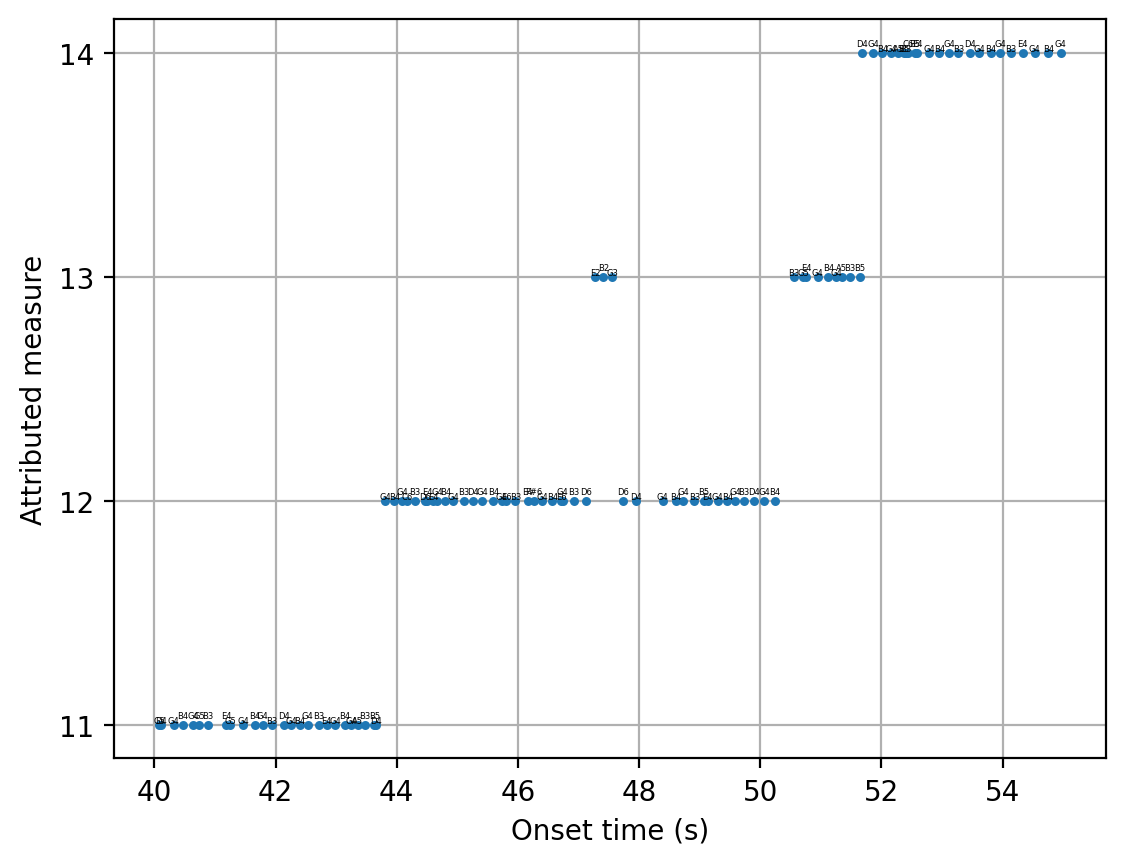

In [26]:
import math
import matplotlib.pyplot as plt

# xabs = np.linspace(0, 100, 1000)
# plt.plot(xabs, ptime_to_stime_map(xabs))

# sub = pna_custom
# sub = pna_custom[(pna_custom['onset_sec'] > 0) & (pna_custom['onset_sec'] < 5)]
sub = pna_custom[(pna_custom['onset_sec'] > 40) & (pna_custom['onset_sec'] < 55)]
# sub = pna_custom[(pna_custom['onset_sec'] > 10) & (pna_custom['onset_sec'] < 25)]

plt.scatter(sub['onset_sec'], sub['measure'], marker='o', s=5, zorder=2)  #, c=sub['velocity'])

# Annotate each point with information 
for i, note in enumerate(sub):
    pitch = note['pitch']
    pitch_spelling = pt.utils.music.midi_pitch_to_pitch_spelling(pitch)
    note_name = pt.utils.music.pitch_spelling_to_note_name(*pitch_spelling)
    txt = note_name
    plt.annotate(txt, (sub['onset_sec'][i], sub['measure'][i] + 0.02*(i%2 == 0)), fontsize=3, ha='center', va='bottom')

plt.yticks(range(min(sub['measure']), max(sub['measure'])+1))
plt.ylabel("Attributed measure")
plt.xlabel("Onset time (s)")
plt.grid()
plt.show()

In [357]:
[n for n in pna_custom if n['measure'] == 12]

[np.void((18.544792, 0.09375, 17803, 90, 36, 60, 1, 0, 'n280', 44.0212287902832, 1056.5094909667969, 12), dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256'), ('stime', '<f8'), ('beat', '<f8'), ('measure', '<i4')]),
 np.void((18.682291, 0.67604166, 17935, 35, 43, 52, 1, 0, 'n282', 44.25, 1062.0, 12), dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256'), ('stime', '<f8'), ('beat', '<f8'), ('measure', '<i4')]),
 np.void((18.777082, 0.58125, 18026, 61, 48, 64, 1, 0, 'n283', 44.5, 1068.0, 12), dtype=[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256'), ('stime', '<f8'), ('b

In [358]:
from partitura.performance import PerformanceLike

PerformanceLike

typing.Union[typing.List[partitura.performance.PerformedPart], partitura.performance.PerformedPart, partitura.performance.Performance]

In [359]:
import itertools

grouped = list(itertools.groupby(sorted(pna_custom, key=lambda x: x['measure']), key=lambda x: int(x['measure'])))

measure_to_pnotes = [np.array(list(notes)) for measure, notes in itertools.groupby(sorted(pna_custom, key=lambda x: x['measure']), key=lambda x: x['measure'])]
# measure_to_pnotes
# measure_to_pnotes[12]
# measure_to_pnotes[12]

In [377]:
from functools import partial
from partitura.performance import PerformedPart

# new_pna = np.concat(measure_to_pnotes[2:5], dtype=pna_custom.dtype)
new_pna = copy.deepcopy(measure_to_pnotes[12])
print(new_pna.dtype)
# print(new_pna)

# Shift all notes to the beginning of the measure
start_offset = float(new_pna['onset_sec'].min())
print(start_offset)
end_offset = (new_pna['onset_sec'] + new_pna['duration_sec']).max()
new_pna['onset_sec'] -= start_offset
# new_pna['duration_sec'] = 0.1
fix_duration_sec = np.vectorize(partial(midi_ticks_to_seconds, mpq=ppart.mpq, ppq=ppart.ppq))
new_pna['duration_sec'] = fix_duration_sec(new_pna["duration_tick"])
print(new_pna)

new_p: PerformedPart = PerformedPart.from_note_array(new_pna)
new_p.ppq = ppart.ppq
new_p.mpq = ppart.mpq

new_controls = [{k: v for k, v in control.items()} for control in ppart.controls if start_offset <= control['time'] <= end_offset]
pprint(new_controls)
for control in new_controls:
    control['time'] -= start_offset
new_p.controls = new_controls
pprint(new_controls)

# from pprint import pprint

# pprint(ppart.controls)


pt.save_performance_midi(new_p, Path("/tmp/test.mid"))

[('onset_sec', '<f4'), ('duration_sec', '<f4'), ('onset_tick', '<i4'), ('duration_tick', '<i4'), ('pitch', '<i4'), ('velocity', '<i4'), ('track', '<i4'), ('channel', '<i4'), ('id', '<U256'), ('stime', '<f8'), ('beat', '<f8'), ('measure', '<i4')]
20.304166793823242
[(0.        , 0.12291667, 19492, 118, 36, 66, 1, 0, 'n307', 48.02734375, 1152.65625   , 13)
 (0.15833282, 0.04479166, 19644,  43, 43, 54, 1, 0, 'n308', 48.25      , 1158.        , 13)
 (0.25416565, 0.04791667, 19736,  46, 48, 66, 1, 0, 'n309', 48.5       , 1164.        , 13)
 (0.36249924, 0.075     , 19840,  72, 50, 66, 1, 0, 'n310', 48.75      , 1170.        , 13)
 (0.45104218, 0.08020833, 19925,  77, 51, 69, 1, 0, 'n311', 49.        , 1176.        , 13)
 (0.5562496 , 0.03958333, 20026,  38, 55, 67, 1, 0, 'n312', 49.25      , 1182.        , 13)
 (0.65312576, 0.06041666, 20119,  58, 60, 73, 1, 0, 'n313', 49.5       , 1188.        , 13)
 (0.7489586 , 0.07916667, 20211,  76, 62, 79, 1, 0, 'n314', 49.75      , 1194.        , 13)

In [378]:
new_p.controls

[{'number': 64, 'time': 0.011458206176758523, 'value': 0, 'track': 0},
 {'number': 64, 'time': 0.09166653951008996, 'value': 38, 'track': 0},
 {'number': 64, 'time': 0.11249987284342566, 'value': 67, 'track': 0},
 {'number': 64, 'time': 0.1302082061767571, 'value': 103, 'track': 0},
 {'number': 64, 'time': 0.15312487284342424, 'value': 127, 'track': 0},
 {'number': 64, 'time': 0.8510415395100921, 'value': 81, 'track': 0},
 {'number': 64, 'time': 0.8697915395100928, 'value': 52, 'track': 0},
 {'number': 64, 'time': 0.8916665395100907, 'value': 0, 'track': 0},
 {'number': 64, 'time': 1.272916539510092, 'value': 44, 'track': 0},
 {'number': 64, 'time': 1.296874872843425, 'value': 78, 'track': 0},
 {'number': 64, 'time': 1.3135415395100907, 'value': 127, 'track': 0},
 {'number': 64, 'time': 1.6729165395100907, 'value': 65, 'track': 0},
 {'number': 64, 'time': 1.694791539510092, 'value': 0, 'track': 0},
 {'number': 64, 'time': 1.7739582061767578, 'value': 24, 'track': 0},
 {'number': 64, 't

In [126]:
pt.save_performance_midi(new_p, Path("/tmp/test.mid"))

In [55]:
pna_as_beat

array([   96.00000143,   215.99999428,     0.        , ...,
       18291.22009277, 18302.13134766, 18331.6607666 ])

In [42]:
mmap([18000.08, 12000.05])

array([38, 25])

In [23]:
import numpy as np

bm = spart.inv_beat_map

x = np.array([bm(ptime_to_stime_map(pna[i]['onset_sec']))
     for i in range(len(pna))]).T

# x = np.array(
#     [list(range(len(pna))), [bm(ptime_to_stime_map(pna[i]['onset_sec']))
#      for i in range(len(pna))]]
# ).T

mmap = spart.measure_number_map
x_measure = np.array([mmap(ptime_to_stime_map(pna[i]['onset_sec'])) for i in range(len(pna))]).T

## Splitting by matching notes

In [28]:
sna = spart.note_array()
pna = ppart.note_array()

In [29]:
matched_note_idxs = pt.musicanalysis.performance_codec.get_matched_notes(sna, pna, alignment)
matched_note_idxs

array([[   8,    0],
       [  10,    1],
       [   9,    2],
       ...,
       [2078, 2059],
       [2079, 2060],
       [2080, 2061]])

In [30]:
pprint(alignment)
pprint(np.unique_counts([a["label"] for a in alignment]))

[{'label': 'match', 'performance_id': 'n8', 'score_id': 'n11-1'},
 {'label': 'match', 'performance_id': 'n10', 'score_id': 'n13-1'},
 {'label': 'match', 'performance_id': 'n9', 'score_id': 'n12-1'},
 {'label': 'match', 'performance_id': 'n7', 'score_id': 'n10-1'},
 {'label': 'match', 'performance_id': 'n6', 'score_id': 'n9-1'},
 {'label': 'match', 'performance_id': 'n5', 'score_id': 'n8-1'},
 {'label': 'match', 'performance_id': 'n0', 'score_id': 'n1-1'},
 {'label': 'match', 'performance_id': 'n1', 'score_id': 'n2-1'},
 {'label': 'match', 'performance_id': 'n4', 'score_id': 'n3-1'},
 {'label': 'match', 'performance_id': 'n3', 'score_id': 'n4-1'},
 {'label': 'match', 'performance_id': 'n2', 'score_id': 'n5-1'},
 {'label': 'match', 'performance_id': 'n12', 'score_id': 'n15-1'},
 {'label': 'match', 'performance_id': 'n14', 'score_id': 'n17-1'},
 {'label': 'match', 'performance_id': 'n13', 'score_id': 'n16-1'},
 {'label': 'match', 'performance_id': 'n11', 'score_id': 'n14-1'},
 {'label': '

In [31]:
# %%timeit
snote_to_pnote = {}
pnote_to_snote = {}
snote_unmatched = []
pnote_unmatched = []
for a in alignment:
    match a["label"]:
        case "match":
            pid = a["performance_id"]
            sid = a["score_id"]
            snote_to_pnote[sid] = pid
            pnote_to_snote[pid] = sid
        case "deletion":
            snote_unmatched.append(a["score_id"])
        case "insertion":
            pnote_unmatched.append(a["performance_id"])
        case _:
            raise ValueError(f"Unknown label {a["label"]}")
# pprint(snote_to_pnote)

In [153]:
from typing import Any


def split_partitura_score_and_performances(
    part: pt.score.Part,
    aligned_performances: pt.performance.PerformedPart,
    alignment: list[dict[str, str]],
    num_measures_per_chunk: int,
    overlap: bool = True,
) -> list[dict[str, Any]]:

    num_measures = len(part.measures)

    if num_measures_per_chunk > num_measures:
        raise ValueError(
            "The number of measures per chunk must be less than the total number of measures."
        )
        
    # Get the matched notes
    snote_to_pnote = {}
    pnote_to_snote = {}
    snote_unmatched = []
    pnote_unmatched = []
    for a in alignment:
        match a["label"]:
            case "match":
                pid = a["performance_id"]
                sid = a["score_id"]
                snote_to_pnote[sid] = pid
                pnote_to_snote[pid] = sid
            case "deletion":
                snote_unmatched.append(a["score_id"])
            case "insertion":
                pnote_unmatched.append(a["performance_id"])
            case _:
                raise ValueError(f"Unknown label {a["label"]}")
    
    # Create a dict to get the performance notes from their name
    # print(aligned_performances.notes)
    pnote_dict = {pnote["id"]: pnote for pnote in aligned_performances.notes}

    chunks = []

    if overlap:
        step = 1
    else:
        step = num_measures_per_chunk
        if num_measures % num_measures_per_chunk != 0:
            print(
                f"Last chunk will only have {num_measures % num_measures_per_chunk} measures."
            )

    # Create all chunks
    for start_measure_idx in range(0, num_measures - num_measures_per_chunk + 1, step):
        # Get the start and end measures of the chunk
        end_measure_idx = min(start_measure_idx + num_measures_per_chunk, num_measures)
        start_measure = part.measures[start_measure_idx]
        end_measure = part.measures[end_measure_idx - 1]
        # print(f"Chunk {start_measure_idx}-{end_measure_idx}")

        # Create a new ScoreVariant
        sv = pt.score.ScoreVariant(part)
        sv.add_segment(start_measure.start, end_measure.end)
        new_score_chunk = sv.create_variant_part()

        # Fix the quarter lengths of the new chunk (see PR #385 of partitura)
        new_score_chunk.set_quarter_duration(0, part.quarter_duration_map(start_measure.start.t))        
        
        # Get the matched notes of the performance
        pnotes: list[pt.performance.PerformedNote] = []
        for snote in new_score_chunk.notes:
            pnote = pnote_dict.get(snote_to_pnote.get(snote.id))
            # We skip unmatched notes, TODO: add them back?
            if pnote is not None:
                pnotes.append(pnote.copy())
        # Fix the times of to start from 0
        p_start = min(pnote["note_on"] for pnote in pnotes)
        p_end = max(pnote["note_on"] for pnote in pnotes)  # consider note_off?
        for pnote in pnotes:
            # print(pnote)
            pnote["note_on"] -= p_start
            pnote["note_off"] -= p_start
        
        # Get the controls
        controls = [copy.copy(control) for control in aligned_performances.controls if p_start <= control["time"] <= p_end]
        for control in controls:
            control["time"] -= p_start
        # print(controls[0])
        # controls[-1]["value"] = 0
        # print(p_start)
        # print(controls)
        
        # print(pnotes)
        new_perf_chunk = pt.performance.PerformedPart(
            notes=[pnote.copy() for pnote in pnotes if pnote is not None],
            controls=controls,
            id=ppart.id,
            ppq=aligned_performances.ppq,
            mpq=aligned_performances.mpq,
        )
        # print(new_perf_chunk.notes)

        # Store the new chunk
        chunks.append(
            {
                "score": new_score_chunk,
                "performance": new_perf_chunk,
                "score_start": start_measure.start.t,
                "performance_start": p_start,
            }
        )

    # Add eventual missing score contextual information on all chunks (clefs, key & time signatures)
    for chunk in chunks:
        # For each contextual information, get it from the context, check against the first measure
        # of the chunk and add it if missing, and then add it to the chunk if needed.
        for contextual_getter, contextual_adder in [
            (
                get_time_signature_map_object_wrapper(part.time_signature_map),
                add_time_signature_if_missing,
            ),
            (
                get_key_signature_map_object_wrapper(part.key_signature_map),
                add_key_signature_if_missing,
            ),
            (get_clef_map_object_wrapper(part.clef_map), add_clefs_if_missing),
        ]:
            contextual_adder(chunk["score"], contextual_getter(chunk["score_start"]))
    
    # Add non-matched notes back to the performance chunks
    ptime_to_stime_map, _ = pt.musicanalysis.performance_codec.get_time_maps_from_alignment(ppart, part, alignment)
    inv_beat_map = part.inv_beat_map
    measure_number_map = part.measure_number_map
    ptime_to_measure_number_map = lambda x: measure_number_map(inv_beat_map(int(ptime_to_stime_map(x))))
    for pnote_id in pnote_unmatched:
        pnote = pnote_dict[pnote_id]
        pnote_measure = ptime_to_measure_number_map(pnote["note_on"])
        related_chunk_idxs = list(range(max(0, pnote_measure - num_measures_per_chunk), min(pnote_measure, num_measures - num_measures_per_chunk + 1)) if overlap else [pnote_measure // num_measures_per_chunk] if 1 <= pnote_measure <= num_measures else [])
        print(
            f"{pnote["id"]} \t "
            f"T{round(pnote["note_on"], 3)}-{round(pnote["note_off"], 3)} \t "
            f"P{pnote["pitch"]} \t "
            f"M{pnote_measure} \t "
            f"Chunks {related_chunk_idxs} \t "
            f"C1 {chunks[related_chunk_idxs[0]]["performance_start"]} \t "
        )
        for i, chunk in enumerate([chunks[chunk_idx] for chunk_idx in related_chunk_idxs]):
            new_pnote = pnote.copy()
            new_pnote["note_on"] -= chunk["performance_start"]
            new_pnote["note_off"] -= chunk["performance_start"]
            chunk["performance"].notes.append(new_pnote)
    
    return chunks

In [156]:
from tqdm import tqdm

nmeas = 8
c = split_partitura_score_and_performances(spart, ppart, alignment, nmeas)

out_test = Path("/tmp/split_tests") / SCORE.relative_to(NASAP_PATH).parent
out_test.mkdir(exist_ok=True, parents=True)

for i, chunk in enumerate(tqdm(c)):
    start = i + 1
    end = i + nmeas
    pt.save_musicxml(chunk["score"], out_test / f"{chunk['score'].id}_{start}-{end}.musicxml")
    pt.save_performance_midi(chunk["performance"], out_test / f"{chunk['performance'].id}_{start}-{end}.mid")
    # break

n1604 	 T108.108-108.186 	 P50 	 M62 	 Chunks [54, 55, 56, 57, 58, 59, 60, 61] 	 C1 93.69166666666666 	 
n2060 	 T147.82-147.901 	 P37 	 M82 	 Chunks [74, 75, 76] 	 C1 131.50104166666668 	 
n281 	 T18.622-18.983 	 P72 	 M12 	 Chunks [4, 5, 6, 7, 8, 9, 10, 11] 	 C1 7.267708333333333 	 
n438 	 T28.757-28.781 	 P70 	 M17 	 Chunks [9, 10, 11, 12, 13, 14, 15, 16] 	 C1 15.116666666666667 	 
n539 	 T36.499-36.542 	 P72 	 M22 	 Chunks [14, 15, 16, 17, 18, 19, 20, 21] 	 C1 23.651041666666668 	 
n668 	 T44.503-44.511 	 P88 	 M27 	 Chunks [19, 20, 21, 22, 23, 24, 25, 26] 	 C1 31.922916666666666 	 
n877 	 T59.049-60.507 	 P79 	 M35 	 Chunks [27, 28, 29, 30, 31, 32, 33, 34] 	 C1 46.208333333333336 	 
n1003 	 T69.507-69.571 	 P77 	 M40 	 Chunks [32, 33, 34, 35, 36, 37, 38, 39] 	 C1 55.090625 	 
n1002 	 T69.48-69.485 	 P86 	 M40 	 Chunks [32, 33, 34, 35, 36, 37, 38, 39] 	 C1 55.090625 	 
n1049 	 T73.02-73.129 	 P88 	 M43 	 Chunks [35, 36, 37, 38, 39, 40, 41, 42] 	 C1 60.22083333333333 	 
n1088 	 T76.

100%|██████████| 77/77 [00:02<00:00, 28.54it/s]


## Multi-performances

In [206]:
from typing import Any


def split_partitura_score_and_performances(
    score: pt.score.Part,
    aligned_performances: list[tuple[pt.performance.PerformedPart, list[dict[str, str]]]],
    num_measures_per_chunk: int,
    overlap: bool = True,
) -> list[dict[str, Any]]:

    num_measures = len(score.measures)

    if num_measures_per_chunk > num_measures:
        raise ValueError(
            "The number of measures per chunk must be less than the total number of measures."
        )
        
    # Get the matched notes
    alignement_mappings = []
    for performance, alignment in aligned_performances:
        snote_to_pnote = {}
        pnote_to_snote = {}
        snote_unmatched = []
        pnote_unmatched = []
        for a in alignment:
            match a["label"]:
                case "match":
                    pid = a["performance_id"]
                    sid = a["score_id"]
                    snote_to_pnote[sid] = pid
                    pnote_to_snote[pid] = sid
                case "deletion":
                    snote_unmatched.append(a["score_id"])
                case "insertion":
                    pnote_unmatched.append(a["performance_id"])
                case _:
                    raise ValueError(f"Unknown label {a["label"]}")
        alignement_mappings.append({
            "sid_to_pid": snote_to_pnote,  # score 
            "pid_to_sid": pnote_to_snote,
            "sid_unmatched": snote_unmatched,
            "pid_unmatched": pnote_unmatched,
            "pid_to_pnote": {pnote["id"]: pnote for pnote in performance.notes},
        })

    chunks = []

    if overlap:
        step = 1
    else:
        step = num_measures_per_chunk
        if num_measures % num_measures_per_chunk != 0:
            print(
                f"Last chunk will only have {num_measures % num_measures_per_chunk} measures."
            )

    # Create all chunks
    for start_measure_idx in range(0, num_measures - num_measures_per_chunk + 1, step):
        # Get the start and end measures of the chunk
        end_measure_idx = min(start_measure_idx + num_measures_per_chunk, num_measures)
        start_measure = score.measures[start_measure_idx]
        end_measure = score.measures[end_measure_idx - 1]
        # print(f"Chunk {start_measure_idx}-{end_measure_idx}")

        # Create a new ScoreVariant
        sv = pt.score.ScoreVariant(score)
        sv.add_segment(start_measure.start, end_measure.end)
        new_score_chunk = sv.create_variant_part()

        # Fix the quarter lengths of the new chunk (see PR #385 of partitura)
        new_score_chunk.set_quarter_duration(0, score.quarter_duration_map(start_measure.start.t))        
        
        # Get the matched notes of all performances
        perf_chunks = {}
        for (performance, _), mapping in zip(aligned_performances, alignement_mappings):
            pnotes: list[pt.performance.PerformedNote] = []
            for snote in new_score_chunk.notes:
                # Get the PerformedNote object corresponding to the score note
                pnote = mapping["pid_to_pnote"].get(mapping["sid_to_pid"].get(snote.id))
                # We skip unmatched notes, will be added back later
                if pnote is not None:
                    pnotes.append(pnote.copy())
            # Fix the times of to start from 0
            p_start = min(pnote["note_on"] for pnote in pnotes)
            p_end = max(pnote["note_on"] for pnote in pnotes)  # consider note_off?
            for pnote in pnotes:
                pnote["note_on"] -= p_start
                pnote["note_off"] -= p_start
            
            # Get the controls
            controls = [copy.copy(control) for control in performance.controls if p_start <= control["time"] <= p_end]
            for control in controls:
                control["time"] -= p_start
            # print(controls[0])
            # controls[-1]["value"] = 0
            # print(p_start)
            # print(controls)
            
            # print(pnotes)
            perf_chunks[performance.id] = {
                    "performance": pt.performance.PerformedPart(
                    notes=[pnote.copy() for pnote in pnotes if pnote is not None],
                    controls=controls,
                    id=performance.id,
                    ppq=performance.ppq,
                    mpq=performance.mpq,
                ),
                "performance_start": p_start,
            }
            # print(new_perf_chunk["performance"].notes)

        # Store the new chunk
        chunks.append(
            {
                "score": new_score_chunk,
                "performances": perf_chunks,
                "score_start": start_measure.start.t,
            }
        )

    # Add eventual missing score contextual information on all chunks (clefs, key & time signatures)
    for chunk in chunks:
        # For each contextual information, get it from the context, check against the first measure
        # of the chunk and add it if missing, and then add it to the chunk if needed.
        for contextual_getter, contextual_adder in [
            (
                get_time_signature_map_object_wrapper(score.time_signature_map),
                add_time_signature_if_missing,
            ),
            (
                get_key_signature_map_object_wrapper(score.key_signature_map),
                add_key_signature_if_missing,
            ),
            (get_clef_map_object_wrapper(score.clef_map), add_clefs_if_missing),
        ]:
            contextual_adder(chunk["score"], contextual_getter(chunk["score_start"]))
    
    # Add non-matched notes back to the performance chunks
    for (performance, alignment), mapping in zip(aligned_performances, alignement_mappings):
        # print(f"Performance {performance.id}")
        ptime_to_stime_map, _ = pt.musicanalysis.performance_codec.get_time_maps_from_alignment(performance, score, alignment)
        inv_beat_map = score.inv_beat_map
        measure_number_map = score.measure_number_map
        ptime_to_measure_number_map = lambda x: measure_number_map(inv_beat_map(int(ptime_to_stime_map(x))))
        for pnote_id in mapping["pid_unmatched"]:
            pnote = mapping["pid_to_pnote"][pnote_id]
            pnote_measure = ptime_to_measure_number_map(pnote["note_on"])
            related_chunk_idxs = list(range(max(0, pnote_measure - num_measures_per_chunk), min(pnote_measure, num_measures - num_measures_per_chunk + 1)) if overlap else [pnote_measure // num_measures_per_chunk] if 1 <= pnote_measure <= num_measures else [])
            # print(
            #     f"{pnote["id"]} \t "
            #     f"T{round(pnote["note_on"], 3)}-{round(pnote["note_off"], 3)} \t "
            #     f"P{pnote["pitch"]} \t "
            #     f"M{pnote_measure} \t "
            #     f"Chunks {related_chunk_idxs} \t "
            #     f"C1 {chunks[related_chunk_idxs[0]]["performance_start"]} \t "
            # )
            for i, chunk in enumerate([chunks[chunk_idx] for chunk_idx in related_chunk_idxs]):
                current_perf_chunk = chunk["performances"][performance.id]
                # print(current_perf_chunk, pnote["note_on"])
                new_pnote = pnote.copy()
                new_pnote["note_on"] -= current_perf_chunk["performance_start"]
                new_pnote["note_off"] -= current_perf_chunk["performance_start"]
                current_perf_chunk["performance"].notes.append(new_pnote)
    
    return chunks

In [201]:
# score_path = Path("/home/gerel/Documents/datasets/nasap-dataset/Chopin/Etudes_op_10/12/xml_score.musicxml")
score_path = Path("/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/xml_score.musicxml")
alignment_paths = list(score_path.parent.glob("*.match"))

print(score_path)
print(alignment_paths)

/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/xml_score.musicxml
[PosixPath('/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/Namirovsky06M.match'), PosixPath('/home/gerel/Documents/datasets/nasap-dataset/Rachmaninoff/Preludes_op_32/5/KorchinskayaKogan03.match')]


In [202]:
# Read all data
score = pt.load_musicxml(score_path)
assert len(score.parts) == 1
score = pt.score.unfold_part_maximal(score.parts[0])

aligned_performances = [
    pt.load_match(alignment_path) for alignment_path in alignment_paths
]
assert all([len(performance.performedparts) == 1 for performance, _ in aligned_performances])
aligned_performances = [(performance.performedparts[0], alignment) for performance, alignment in aligned_performances]
for (p, _), path in zip(aligned_performances, alignment_paths):
    p.id = path.stem

In [205]:
# Split
nmeas = 8
# c = split_partitura_score_and_performances(score, aligned_performances, nmeas)
c = split_partitura_score_and_performances(score, [], nmeas)

out_test = Path("/tmp/split_tests") / score_path.relative_to(NASAP_PATH).parent / f"chunked={nmeas}"
out_test.mkdir(exist_ok=True, parents=True)

for i, chunk in enumerate(tqdm(c)):
    start = i + 1
    end = i + nmeas
    out_dir = out_test / f"measures_{start}-{end}"
    out_dir.mkdir(exist_ok=True)
    pt.save_musicxml(chunk["score"], out_dir / f"{chunk['score'].id}_{start}-{end}.musicxml")
    for perf_id, perf_chunk in chunk["performances"].items():
        pt.save_performance_midi(perf_chunk["performance"], out_dir / f"{perf_id}_{start}-{end}.mid")
    # break

100%|██████████| 34/34 [00:01<00:00, 33.22it/s]


# Test implemented version

In [10]:
from src.data.components.asap_dataset import AsapDataset

ds = AsapDataset(NASAP_PATH)

In [22]:
ds.split_asap_dataset(
    new_dataset_path=Path("/tmp/split_asap"),
    num_measures_per_chunk=8,
    overlap=True,
    skip_already_split=True,
    n_jobs=-1,
    progress=True,
)

  0%|          | 2.23M/1.70G [00:06<52:21, 540kB/s]  [rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Bach/Prelude/bwv_874/xml_score.musicxml: Tuplet start time is after tuplet stop time
  0%|          | 6.67M/1.70G [00:07<13:01, 2.17MB/s][rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Beethoven/Piano_Sonatas/18-3/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Balakirev/Islamey/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Beethoven/Piano_Sonatas/16-2/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Beethoven/Piano_Sonatas/17-3/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Beethoven/Piano_Sonatas/13-4/xml_sc

8440 matched notes | 159 unmatched score notes | 125 unmatched performance notes | 96.74% matched ratio
8486 matched notes | 113 unmatched score notes | 35 unmatched performance notes | 98.29% matched ratio
2676 matched notes | 4048 unmatched score notes | 3910 unmatched performance notes | 25.16% matched ratio
2680 matched notes | 4044 unmatched score notes | 3942 unmatched performance notes | 25.13% matched ratio


[rank: 0] Note n3785 seems to start before chunk 7 (300.009375 < 300.0833333333333). Clipping start to 0.
[rank: 0] Note n2 seems to end before chunk 1 (2.189583333333333 < 2.2020833333333334). Skipping note.
[rank: 0] Note n2040 seems to end before chunk 7 (173.171875 < 174.25833333333333). Skipping note.
  3%|▎         | 44.4M/1.70G [02:24<2:08:15, 215kB/s][rank: 0] Note n2638 seems to start before chunk 7 (320.95625 < 320.96666666666664). Clipping start to 0.
[rank: 0] Dropping 3 performances with a note matched ratio below 90%.
[rank: 0] Dropping 3 performances with a note matched ratio below 90%.
[rank: 0] All performances were dropped. Aborting split.
[rank: 0] Dropping 1 performances with a note matched ratio below 90%.
[rank: 0] Dropping 2 performances with a note matched ratio below 90%.
/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/hom

2955 matched notes | 78 unmatched score notes | 68 unmatched performance notes | 95.29% matched ratio
2197 matched notes | 836 unmatched score notes | 25 unmatched performance notes | 71.84% matched ratio
3359 matched notes | 140 unmatched score notes | 100 unmatched performance notes | 93.33% matched ratio
5406 matched notes | 65 unmatched score notes | 125 unmatched performance notes | 96.60% matched ratio
4000 matched notes | 1471 unmatched score notes | 122 unmatched performance notes | 71.52% matched ratio
3983 matched notes | 1488 unmatched score notes | 131 unmatched performance notes | 71.10% matched ratio
5255 matched notes | 216 unmatched score notes | 56 unmatched performance notes | 95.08% matched ratio
5332 matched notes | 139 unmatched score notes | 145 unmatched performance notes | 94.94% matched ratio
5313 matched notes | 158 unmatched score notes | 130 unmatched performance notes | 94.86% matched ratio
5369 matched notes | 102 unmatched score notes | 421 unmatched perf

[rank: 0] Note n2208 seems to end before chunk 7 (265.26875 < 265.40208333333334). Skipping note.
[rank: 0] Note n2209 seems to end before chunk 7 (265.26666666666665 < 265.40208333333334). Skipping note.
[rank: 0] Note n2207 seems to end before chunk 7 (265.28020833333335 < 265.40208333333334). Skipping note.
[rank: 0] Note n2205 seems to end before chunk 7 (265.2760416666667 < 265.40208333333334). Skipping note.
[rank: 0] Note n2206 seems to end before chunk 7 (265.2552083333333 < 265.40208333333334). Skipping note.
[rank: 0] Note n2204 seems to end before chunk 7 (265.25625 < 265.40208333333334). Skipping note.
[rank: 0] Note n5349 seems to start before chunk 7 (575.8927083333333 < 575.896875). Clipping start to 0.
[rank: 0] Note n2212 seems to end before chunk 7 (295.90208333333334 < 296.10520833333334). Skipping note.
[rank: 0] Note n2214 seems to end before chunk 7 (295.95416666666665 < 296.10520833333334). Skipping note.
[rank: 0] Note n2213 seems to end before chunk 7 (295.9729

1609 matched notes | 205 unmatched score notes | 172 unmatched performance notes | 81.02% matched ratio
3760 matched notes | 1562 unmatched score notes | 120 unmatched performance notes | 69.09% matched ratio
3710 matched notes | 1612 unmatched score notes | 104 unmatched performance notes | 68.37% matched ratio
5231 matched notes | 91 unmatched score notes | 68 unmatched performance notes | 97.05% matched ratio
3792 matched notes | 1530 unmatched score notes | 128 unmatched performance notes | 69.58% matched ratio
5124 matched notes | 198 unmatched score notes | 156 unmatched performance notes | 93.54% matched ratio
3943 matched notes | 98 unmatched score notes | 110 unmatched performance notes | 94.99% matched ratio
3953 matched notes | 88 unmatched score notes | 76 unmatched performance notes | 96.02% matched ratio
3980 matched notes | 61 unmatched score notes | 51 unmatched performance notes | 97.26% matched ratio
3930 matched notes | 111 unmatched score notes | 81 unmatched perfor

... (10 outputs left out)

[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Ravel/Gaspard_de_la_Nuit/1_Ondine/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Ravel/Miroirs/4_Alborada_del_gracioso/xml_score.musicxml: Tuplet start time is after tuplet stop time
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Schubert/Impromptu_op.90_D.899/1/xml_score.musicxml: Tuplet start time is after tuplet stop time
  5%|▌         | 90.5M/1.70G [08:04<18:04:09, 24.7kB/s][rank: 0] Dropping 7 performances with a note matched ratio below 90%.
[rank: 0] Error loading /home/gerel/Documents/datasets/nasap-dataset/Schubert/Impromptu_op142/1/Lisiecki10M.match: Filename does not exist
[rank: 0] Dropping 7 performances with a note matched ratio below 90%.
[rank: 0] All performances were dropped. Aborting split.
[rank: 0] Dropping 1 performances with a note matched ratio below 90%.
[rank: 0] All performances were 

496 matched notes | 14 unmatched score notes | 14 unmatched performance notes | 94.66% matched ratio
496 matched notes | 14 unmatched score notes | 28 unmatched performance notes | 92.19% matched ratio
498 matched notes | 12 unmatched score notes | 19 unmatched performance notes | 94.14% matched ratio
496 matched notes | 14 unmatched score notes | 20 unmatched performance notes | 93.58% matched ratio
497 matched notes | 13 unmatched score notes | 26 unmatched performance notes | 92.72% matched ratio
497 matched notes | 13 unmatched score notes | 28 unmatched performance notes | 92.38% matched ratio
2569 matched notes | 73 unmatched score notes | 59 unmatched performance notes | 95.11% matched ratio
2603 matched notes | 39 unmatched score notes | 33 unmatched performance notes | 97.31% matched ratio
2582 matched notes | 60 unmatched score notes | 64 unmatched performance notes | 95.42% matched ratio
2525 matched notes | 117 unmatched score notes | 70 unmatched performance notes | 93.10%

Traceback (most recent call last):
  File "<frozen runpy>", line 189, in _run_module_as_main
  File "<frozen runpy>", line 112, in _get_module_details
  File "/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/joblib/__init__.py", line 114, in <module>
    from .memory import Memory
  File "/home/gerel/miniconda3/envs/gramscore/lib/python3.12/site-packages/joblib/memory.py", line 12, in <module>
    import asyncio
  File "/home/gerel/miniconda3/envs/gramscore/lib/python3.12/asyncio/__init__.py", line 8, in <module>
    from .base_events import *
  File "/home/gerel/miniconda3/envs/gramscore/lib/python3.12/asyncio/base_events.py", line 18, in <module>
    import concurrent.futures
  File "/home/gerel/miniconda3/envs/gramscore/lib/python3.12/concurrent/futures/__init__.py", line 8, in <module>
    from concurrent.futures._base import (FIRST_COMPLETED,
  File "/home/gerel/miniconda3/envs/gramscore/lib/python3.12/concurrent/futures/_base.py", line 7, in <module>
    import 

KeyboardInterrupt: 